# 1854 Cholera Advanced1: routes and reachable nodes

**PHI outbreak investigations · 20–30 minutes · original browser companion**

An original PHI-Case-Studies companion using seven invented graph nodes and edge times to expose topology, inclusive travel budgets, unreachable locations and the limits of an isochrone.

**Learning question:** How do a travel budget and one missing connection change reachability while an unreachable node remains unknown?

**Data status:** original synthetic teaching fixture; no historical measurements, real patient records, source map or external data requests. This bounded companion runs with standard-library Python and IPython in the atlas Lab. Linked source courses have their own rights and runtimes.


## Predict before running

Start with [Basic](../cholera-1854-basic/index.ipynb), then ask why drawn distance and travel cost can disagree. Every edge here must have a positive finite time in assumed minutes and can be traversed both ways. Coordinates affect only the drawing. S is the origin; U has no connection. Predict whether E is included by an inclusive three-minute budget, and whether an unconnected U should be zero, large or unknown. The shortest-path calculation repeatedly extends the cheapest discovered route and keeps unknown until a route exists.

Write a prediction and an assumption. Run cells in order with **Shift+Enter** or **Run → Run All Cells**. The first code cell supplies local SVG display helpers; the next performs the calculation. Every figure has a title/description and printed values as a text alternative. Allow up to 60 seconds per cell on first runtime load; the fixture calculation normally takes seconds and needs no installs, account or credentials.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Assumed undirected edge minutes: [('S', 'A', 2), ('S', 'B', 1), ('B', 'D', 1), ('D', 'E', 1), ('A', 'C', 2), ('C', 'E', 4)]
Shortest minutes from S: {'S': 0, 'A': 2, 'B': 1, 'C': 4, 'D': 2, 'E': 3, 'U': 'unknown (unreachable)'}
Inclusive budget <= 3 minutes: 5/7 graph nodes; reached: ['S', 'A', 'B', 'D', 'E']
At budget boundary: ['E'] ; unreachable remains unknown: ['U']
Graph-node denominator includes S and U. This is not an accessible-area polygon or observed pump use.


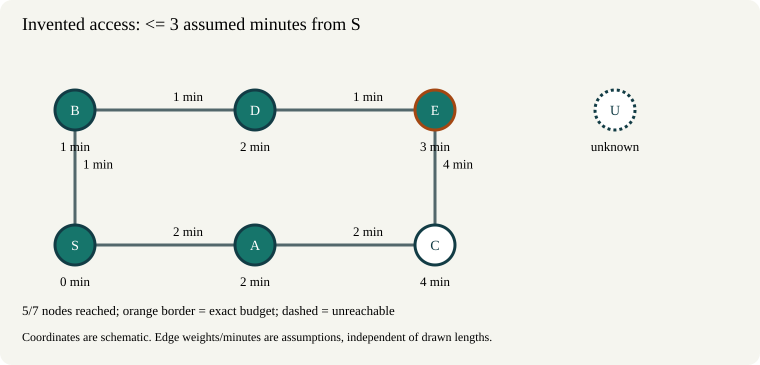

In [2]:
from heapq import heappop, heappush
from math import isfinite

# Undirected invented graph. Coordinates draw a schematic; edge times are assumed minutes.
nodes = {'S': (0, 0), 'A': (1, 0), 'B': (0, 1), 'C': (2, 0),
         'D': (1, 1), 'E': (2, 1), 'U': (3, 1)}
edges = [('S', 'A', 2), ('S', 'B', 1), ('B', 'D', 1),
         ('D', 'E', 1), ('A', 'C', 2), ('C', 'E', 4)]
budget = 3

def shortest_costs(node_names, links, origin):
    adjacency = {name: [] for name in node_names}
    for left, right, minutes in links:
        if not isfinite(minutes) or minutes <= 0:
            raise ValueError('Edge times must be positive finite minutes')
        adjacency[left].append((right, minutes))
        adjacency[right].append((left, minutes))
    costs = {name: None for name in node_names}
    costs[origin] = 0
    queue = [(0, origin)]
    while queue:
        cost, name = heappop(queue)
        if cost != costs[name]:
            continue
        for other, minutes in adjacency[name]:
            candidate = cost + minutes
            if costs[other] is None or candidate < costs[other]:
                costs[other] = candidate
                heappush(queue, (candidate, other))
    return costs

costs = shortest_costs(nodes, edges, 'S')
reached = [name for name, cost in costs.items() if cost is not None and cost <= budget]
boundary = [name for name, cost in costs.items() if cost == budget]
unknown = [name for name, cost in costs.items() if cost is None]
print('Assumed undirected edge minutes:', edges)
print('Shortest minutes from S:', {name: ('unknown (unreachable)' if value is None else value) for name, value in costs.items()})
print(f'Inclusive budget <= {budget} minutes: {len(reached)}/{len(nodes)} graph nodes; reached:', reached)
print('At budget boundary:', boundary, '; unreachable remains unknown:', unknown)
print('Graph-node denominator includes S and U. This is not an accessible-area polygon or observed pump use.')

def project(point):
    x, y = point
    return 75 + x * 180, 245 - y * 135
body = f'<text x="22" y="30" font-size="18">Invented access: &lt;= {budget} assumed minutes from S</text>'
for left, right, minutes in edges:
    x1, y1 = project(nodes[left]); x2, y2 = project(nodes[right])
    body += f'<path d="M{x1} {y1}L{x2} {y2}" stroke="#52676b" stroke-width="3"/>'
    body += f'<text x="{(x1+x2)/2+8}" y="{(y1+y2)/2-9}" font-size="13">{minutes} min</text>'
for name, coordinate in nodes.items():
    x, y = project(coordinate)
    fill = '#16756b' if name in reached else '#ffffff'
    stroke = '#a34712' if name in boundary else '#123c45'
    dash = ' stroke-dasharray="3 3"' if costs[name] is None else ''
    body += f'<circle cx="{x}" cy="{y}" r="20" fill="{fill}" stroke="{stroke}" stroke-width="3"{dash}/>'
    body += f'<text x="{x}" y="{y+5}" text-anchor="middle" font-size="14" fill="{("white" if name in reached else "#123c45")}">{escape(name)}</text>'
    label = 'unknown' if costs[name] is None else f'{costs[name]} min'
    body += f'<text x="{x}" y="{y+41}" text-anchor="middle" font-size="13">{label}</text>'
body += f'<text x="22" y="315" font-size="13">{len(reached)}/{len(nodes)} nodes reached; orange border = exact budget; dashed = unreachable</text>'
body += '<text x="22" y="341" font-size="12">Coordinates are schematic. Edge weights/minutes are assumptions, independent of drawn lengths.</text>'
description = f'Inclusive {budget}-minute budget reaches {len(reached)} of {len(nodes)} graph nodes. Boundary: {boundary}. ' + '; '.join(f'{name}: {"unknown" if value is None else str(value)+" minutes"}' for name, value in costs.items())
svg(body, 'Synthetic Cholera Advanced1: network access', description, height=365)


## Interpret the result

From S the default costs are S=0, A=2, B=1, D=2, E=3, C=4 minutes; U is unreachable/unknown. The inclusive budget reaches **5/7 graph nodes**, counting the origin S and including E exactly at the boundary. The orange ring marks that equality; a dashed outline marks unknown. These seven nodes are the denominator, not seven households or a population sample. A node set is not an exact accessible-area polygon, and shortest routes under assumed weights are not observed walking behavior or pump use.

## Change one thing

Change `budget = 3` to `budget = 2`: the reached count becomes **4/7**. Restore 3, then remove only `('B', 'D', 1)` from `edges` (repair the list comma if needed). E now costs 8 and D 9 minutes through A–C–E; only S, A and B meet the budget, **3/7**. U must remain unknown in text and SVG. Restore the edge and record which conclusion changed because of a budget assumption and which changed because of topology. Do not silently treat unreachable as a zero-minute trip.

Save your edited experiment with **File → Save and Export Notebook As → Notebook** or the file browser's Download command. Browser storage belongs to this browser/profile; it is not a GitHub commit or a shared patient database. Restart the kernel and Run All to check your saved version.


## Put the method in context

The five source lessons progress from OSMnx/Folium graph construction to network distances and connectors, projected travel-time isochrones, counting locations, and further questions. A 400 m source assumption is a teaching choice, not a universal walkability standard. Convex hulls/buffers approximate a reachable shape and may include places with no supported route; point counts also differ from death-weighted counts in Basic. Real access involves crossings, speed, mobility, time, exclusion and actual routes. The later Jupyterlite source is the primary course here; the earlier native repository is linked as background only. Keep Snow's household/water-use inquiry in view: a route drawing does not establish use or cause.


## 1854 Cholera Advanced1: routes and reachable nodes: inspected source notebooks

**Creators:** PHI-Case-Studies and contributors; the Cholera notebooks list contact credits for Herman Tolentino, Jan MacGregor, James Tobias and Zhanar Haimovich. Contacts do not establish sole authorship.

**Repository:** [PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1). [Reviewed README](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/README.md), full commit `8bde848d13d71602b2b32c62e5d4b4957e4a45a1`, branch `main`, inspected 2026-11-02.

This later Jupyterlite source is primary. Its published deployment and root notebook paths were observed in the pinned deployment workflow and public manifest; its generic template README's demo is not the Cholera course. OSMnx/NetworkX/Folium workflows and external tiles need separate support checks.

**Source rights:** Root LICENSE: GNU GPLv3; content/LICENSE: Apache 2.0, with Apache wording in the content README. Both layers are recorded; no blanket resolution is asserted.

| Inspected source file | What the source teaches |
|---|---|
| [content/NB01-Cholera-Case-Study-OpenStreetMaps-Networkx.ipynb](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/content/NB01-Cholera-Case-Study-OpenStreetMaps-Networkx.ipynb) | OSMnx street graph and Folium overlay |
| [content/NB02-Cholera-Case-Study-OpenStreetMaps-Networkx.ipynb](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/content/NB02-Cholera-Case-Study-OpenStreetMaps-Networkx.ipynb) | Pairwise network distances, nearest-node connectors and a 400 m walkability assumption |
| [content/NB03-Cholera-Case-Study-Isochrone-Map.ipynb](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/content/NB03-Cholera-Case-Study-Isochrone-Map.ipynb) | Projected walking times and convex-hull/buffer approximations |
| [content/NB04-Cholera-Case-Study-Isochrone-Map.ipynb](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/content/NB04-Cholera-Case-Study-Isochrone-Map.ipynb) | Point-location counts within isochrones, distinct from death weights |
| [content/NB05-Cholera-Case-Study-Inspiration-and-To-Do-List.ipynb](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/content/NB05-Cholera-Case-Study-Inspiration-and-To-Do-List.ipynb) | Further work, including synthetic time series |

[Root license at the inspected commit](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/LICENSE).

The [published contents manifest](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/api/contents/all.json) was inspected 2026-11-02. The [existing source audit](https://jltobias.github.io/JupyterLite-Learning-Atlas/catalog/launch-checks.json) records its dated URL, source commit, confirmed course notebook basenames and canonical-JSON SHA-256 under `manifest_evidence`, separate from launch rows. This confirms filenames, not source execution or provider behavior. The source deployment is also evidenced by its pinned workflow below.
[Content license](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/content/LICENSE) and [content README](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/content/README.md) retain the separate Apache wording.

The [pinned deployment workflow](https://github.com/PHI-Case-Studies/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/blob/8bde848d13d71602b2b32c62e5d4b4957e4a45a1/.github/workflows/deploy.yml) and [published manifest](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/api/contents/all.json) establish the separately observed course route. The earlier [native original README](https://github.com/PHI-Case-Studies/1854-Cholera-Outbreak-London-Advanced-1/blob/97a1d13dfb23032387ed23804e3d6f4dbc99aec7/README.md), master commit `97a1d13dfb23032387ed23804e3d6f4dbc99aec7`, describes Notebook/Docker/Binder. It remains background continuation, not a duplicate atlas chapter.


## Source launch resources and runtime limits

- [Open source course](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/) — Course deployment observed in pinned workflow and public manifest; separate source runtime. **HTTP 200 - entry only; checked 2026-11-02.**
- [Open source Lab](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/lab/index.html) — Published source Lab entry; execution and provider behavior not certified. **HTTP 200 - entry only; checked 2026-11-02.**
- [Run source lesson 1](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/lab/index.html?path=NB01-Cholera-Case-Study-OpenStreetMaps-Networkx.ipynb) — Exact root notebook path confirmed in published manifest; source execution not certified. **HTTP 200 - entry only; checked 2026-11-02.**
- [Run source lesson 2](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/lab/index.html?path=NB02-Cholera-Case-Study-OpenStreetMaps-Networkx.ipynb) — Exact root notebook path confirmed in published manifest; source execution not certified. **HTTP 200 - entry only; checked 2026-11-02.**
- [Run source lesson 3](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/lab/index.html?path=NB03-Cholera-Case-Study-Isochrone-Map.ipynb) — Exact root notebook path confirmed in published manifest; source execution not certified. **HTTP 200 - entry only; checked 2026-11-02.**
- [Run source lesson 4](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/lab/index.html?path=NB04-Cholera-Case-Study-Isochrone-Map.ipynb) — Exact root notebook path confirmed in published manifest; source execution not certified. **HTTP 200 - entry only; checked 2026-11-02.**
- [Run source lesson 5](https://phi-case-studies.github.io/Jupyterlite-1854-Cholera-Outbreak-London-Advanced-1/lab/index.html?path=NB05-Cholera-Case-Study-Inspiration-and-To-Do-List.ipynb) — Exact root notebook path confirmed in published manifest; source execution not certified. **HTTP 200 - entry only; checked 2026-11-02.**

These dated GET checks establish entry reachability only. The Basic/Advanced1 notebook filenames were also present in published manifests; no source execution, widget, tile/provider behavior or Binder session is certified. No Binder build is triggered by these atlas activities. Source continuation may require packages, networking and provider terms absent from the default atlas runtime.


## Sources, attribution and use

- **Snow, John (1855).** *On the Mode of Communication of Cholera*, 2nd ed., London: John Churchill, pp. 38–55. [Primary transcription and map context, UCLA](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_a.html). Credit Charles Frederick Cheffins for historical maps drawn for Snow, and Ralph R. Frerichs and contributors for UCLA archive/curation. Historical maps are linked, never reproduced.
- **Brody, H.; Rip, M. R.; Vinten-Johansen, P.; Paneth, N.; Rachman, S. (2000).** *Map-making and myth-making in Broad Street: the London cholera epidemic, 1854.* Lancet **356**(9223), 64–68. [DOI](https://doi.org/10.1016/S0140-6736(00)02442-9), [author reprint](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_f.html). Snow's water hypothesis preceded the famous map; a map alone did not establish an intervention effect.
- **UCLA Department of Epidemiology, Ralph R. Frerichs and contributors.** [Historical investigation](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_d.html) and [Henry Whitehead context](https://epi-snow.ph.ucla.edu/Stream2_BSPoutbreak_e.html). Household inquiries, Whitehead and local officials contributed; attacks were already declining before the pump handle was removed on 8 September 1854.
- **CDC (2004).** *150th Anniversary of John Snow and the Pump Handle.* MMWR **53**(34), 783. [Historical overview](https://www.cdc.gov/mmwr/preview/mmwrhtml/mm5334a1.htm). A retrospective account is not a randomized counterfactual comparison.
- **World Health Organization (29 September 2026).** [*Cholera* fact sheet](https://www.who.int/news-room/fact-sheets/detail/cholera). Contaminated food/water, safe water, sanitation and community work provide context; this activity supplies no burden or treatment estimate.

- **NetworkX contributors.** [Weighted shortest paths](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html) and [connected components](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.components.connected_components.html), algorithm background only. No NetworkX code/examples are copied and no package installation is needed.
- **SciPy contributors.** [Voronoi method documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Voronoi.html), source-method context only. The atlas samples a finite nearest-site grid rather than constructing exact Voronoi polygons; SciPy is not installed by these activities.
- **OpenStreetMap contributors.** [Copyright and ODbL attribution](https://www.openstreetmap.org/copyright). Source streets/buildings and Folium/CARTO tiles have separate data/provider terms. All atlas geometry is invented; no OSM graph, footprint, tile or historical basemap is bundled or downloaded. Retain required attribution in source continuations.
- **Upstream software communities:** pandas, NumPy, Folium, OSMnx, NetworkX, GeoPandas, Shapely, SciPy, Bokeh and Plotly support the linked source courses. The original atlas activities execute only Python's standard library and IPython display, under the atlas's existing runtime notices.

All summaries, code, synthetic fixtures and SVGs here are newly authored: MIT executable code; CC BY 4.0 narrative, fixtures and figures, James L. Tobias and JupyterLite Learning Atlas contributors (2026). No source code/prose/data/imagery, patient records, pickles, saved graphs or map tiles are copied. Source rights remain with their creators; public access and shared contributors imply no blanket relicensing or endorsement.

[Central references](../../references.ipynb) · [Visual provenance](../../visual-provenance.ipynb)


## Continue the investigation

Basic → Advanced1 → Advanced2 → MDR-TB is the suggested order.

[1854 Cholera Basic: dots, counts and centres](../cholera-1854-basic/index.ipynb) · [1854 Cholera Advanced2: nearest sites, ties and buildings](../cholera-1854-advanced-2/index.ipynb) · [2005 MDR-TB Thailand: contact evidence and unknown results](../mdr-tb-thailand-2005/index.ipynb)

[Browser Python](../../foundations/browser-python.ipynb) · [Spatial thinking](../../foundations/spatial-thinking.ipynb) · [Global-health synthesis](../../synthesis/global-health.ipynb) · [Learning routes](../../index.ipynb)
